# 07 · Late Delivery: Data Audit and Leakage Control

**Project:** Enterprise Supply Chain Intelligence Platform (DataCo)

This notebook sets the rules for the whole late-delivery model before any algorithm is trained. It fixes four things:

1. **The prediction target:** exactly what "late" means and how it behaves over time
2. **The prediction timing:** the moment the prediction is made, and so what information is allowed
3. **The safe features:** every excluded column has a stated reason, and the exclusions are checked with data
4. **The evaluation boundaries:** a chronological train / validation / test split, saved once and reused by notebooks 08 and 09

Many columns in the engineered table (delivery days, delay, delivery status, late-rate aggregates) are built from the delivery outcome itself. A model trained on them looks perfect and is useless in production, because none of that exists when an order is placed. Deciding this properly matters more than the choice of algorithm.

**Outputs:** `model_input.csv.gz` (features, target, split label) and `feature_manifest.json` (feature lists, exclusions, split boundaries).

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 140)

# ---- Paths (Windows) ----
PROJECT_ROOT = Path('E:/Supply Chain Project')
DATA_PATH = PROJECT_ROOT / 'Datasets/Cleaned Data/supply_chain_orders_processed.csv'   # input FILE
OUT_DIR   = PROJECT_ROOT / 'Datasets/Model Input'                                       # output FOLDER
FIG_DIR   = PROJECT_ROOT / 'Reports/Figures'                                            # output FOLDER

assert DATA_PATH.is_file(), f'Input file not found: {DATA_PATH}'
for folder in (OUT_DIR, FIG_DIR):
    assert not folder.is_file(), f'{folder} is a file. It must be a folder.'
    folder.mkdir(parents=True, exist_ok=True)

TARGET   = 'Late_delivery_risk'
DATE_COL = 'order date (DateOrders)'
ORDER_ID = 'Order Id'
SEED     = 42

# chronological split shares
TRAIN_SHARE, VAL_SHARE = 0.68, 0.12      # the remaining 20% is the test period

## 1. Load the data

In [2]:
df = pd.read_csv(DATA_PATH)
df[DATE_COL] = pd.to_datetime(df[DATE_COL])
print(f'Rows: {len(df):,} | Columns: {df.shape[1]}')
print(f'Order dates: {df[DATE_COL].min().date()}  ->  {df[DATE_COL].max().date()}')
if ORDER_ID in df.columns:
    print(f'Distinct orders: {df[ORDER_ID].nunique():,} (rows are order items, so one order can have several rows)')
df.dtypes.value_counts()

Rows: 180,519 | Columns: 103
Order dates: 2015-01-01  ->  2018-01-31
Distinct orders: 65,752 (rows are order items, so one order can have several rows)


int64             34
float64           34
object            22
bool              12
datetime64[ns]     1
Name: count, dtype: int64

## 2. The prediction target

### 2.1 What "late" means
`Late_delivery_risk` should mean the real shipping time was longer than the scheduled shipping time. I check that against the two day-count columns instead of assuming it. These columns are used here only to understand the target. They are never model inputs.

In [3]:
real, sched = 'Days for shipping (real)', 'Days for shipment (scheduled)'
if {real, sched}.issubset(df.columns):
    derived = (df[real] > df[sched]).astype(int)
    agree = (derived == df[TARGET]).mean()
    print(f'Agreement between "{real} > {sched}" and {TARGET}: {agree:.2%}')
    display(pd.crosstab(df[TARGET], derived, rownames=['Late_delivery_risk'], colnames=['real > scheduled']))
else:
    print('Day-count columns not found. Skipping the definition check.')

Agreement between "Days for shipping (real) > Days for shipment (scheduled)" and Late_delivery_risk: 97.55%


real > scheduled,0,1
Late_delivery_risk,,
0,77119,4423
1,0,98977


### 2.2 Class balance and drift over time
Two things to know: how balanced the classes are, and whether the late rate is stable over time. The second one decides how the data must be split.

Late delivery rate: 54.83%  (on time: 45.17%)


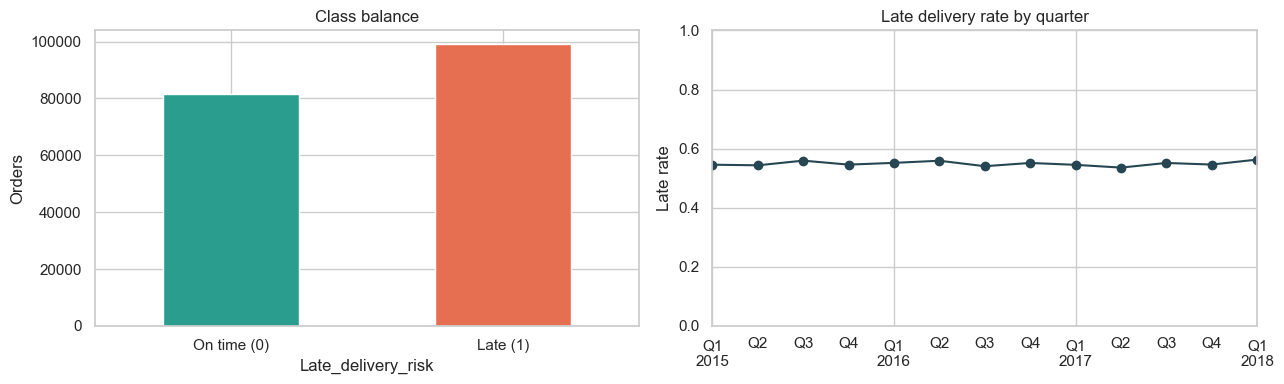

In [4]:
rate = df[TARGET].mean()
print(f'Late delivery rate: {rate:.2%}  (on time: {1-rate:.2%})')

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df[TARGET].value_counts().sort_index().plot(kind='bar', ax=ax[0], color=['#2a9d8f', '#e76f51'])
ax[0].set_xticklabels(['On time (0)', 'Late (1)'], rotation=0)
ax[0].set_title('Class balance'); ax[0].set_ylabel('Orders')

by_q = df.groupby(df[DATE_COL].dt.to_period('Q'))[TARGET].mean()
by_q.plot(marker='o', ax=ax[1], color='#264653')
ax[1].set_title('Late delivery rate by quarter'); ax[1].set_ylabel('Late rate'); ax[1].set_xlabel('')
ax[1].set_ylim(0, 1)
plt.tight_layout(); plt.savefig(FIG_DIR / '01_target_overview.png', dpi=150, bbox_inches='tight'); plt.show()

In [5]:
# Late rate by shipping mode. The raw column was one-hot encoded earlier, so I rebuild the label.
mode_cols = [c for c in df.columns if c.startswith('Shipping Mode_')]
mode = pd.Series('First Class', index=df.index)
for c in mode_cols:
    mode[df[c].astype(bool)] = c.replace('Shipping Mode_', '')
summary = (df.assign(shipping_mode=mode)
             .groupby('shipping_mode')[TARGET]
             .agg(orders='size', late_rate='mean')
             .sort_values('late_rate', ascending=False))
summary['late_rate'] = summary['late_rate'].round(3)
summary

,orders,late_rate
shipping_mode,,
First Class,27814,0.953
Second Class,35216,0.766
Same Day,9737,0.457
Standard Class,107752,0.381


Shipping mode alone separates late and on-time orders strongly. That is a legitimate signal, since the mode is chosen when the order is placed. It also sets the baseline any ML model has to beat, and notebook 08 uses it that way.

## 3. Prediction timing and safe features

**The prediction is made at order placement.** At that moment the business knows what was ordered, from where, to where, how it will be paid for, which shipping mode was chosen and how many days were promised. It does not yet know how the shipment actually performed.

| Known at order placement (allowed) | Not known at order placement (excluded) |
|---|---|
| Product, category, department, price, quantity, discount | Actual shipping days, delivery time, delay |
| Shipping mode chosen, scheduled shipping days | Delivery status, early or late flags |
| Destination region, country, coordinates | Order status after processing, shipping date |
| Payment type, order calendar features | Late-rate averages and risk scores built from outcomes |
| Customer's order count **up to this date** | Totals computed over the whole 2015–2018 history |

Every column is sorted into one of the groups below, with the reason recorded so the decision can be reviewed.

In [6]:
LEAKAGE = {
    # Built from, or equal to, the delivery outcome
    'outcome_or_target_derived': [
        'Days for shipping (real)', 'delivery_time_days', 'shipping_delay_days',
        'is_late', 'is_early', 'Delivery Status',
        'delivery_performance_category_Late', 'delivery_performance_category_On Time',
        'delivery_risk_score', 'high_risk_order_flag', 'shipping_efficiency_score',
        'shipping_mode_avg_delay', 'shipping_mode_late_rate',
        'region_late_rate', 'customer_late_order_rate', 'preferred_shipping_mode',
    ],
    # Only known after the order has been processed or shipped
    'known_only_after_order': [
        'Order Status', 'shipping date (DateOrders)',
    ],
    # Aggregates computed over the full 2015-2018 history, so early orders "see" the future
    'full_history_aggregates': [
        'customer_order_count', 'customer_total_sales', 'customer_avg_order_value',
        'customer_is_repeat', 'customer_value_segment', 'purchase_frequency', 'avg_basket_size',
        'product_revenue', 'product_order_count', 'product_avg_profit',
        'product_sales_rank', 'product_demand_category',
        'region_total_revenue', 'region_total_profit', 'category_avg_margin',
        'Category Name_freq_encoded', 'Order City_freq_encoded', 'Order Country_freq_encoded',
    ],
    # A calendar year drifts outside the training range under a chronological split
    'time_trend': [
        'order_year',
    ],
    # Identifiers and personal data: no predictive meaning, and a privacy risk
    'identifiers_pii': [
        'Customer Id', 'Customer Fname', 'Customer Lname', 'Customer Zipcode',
        'Order Id', 'Order Item Id', 'Order Customer Id', 'Order Item Cardprod Id',
        'Product Card Id', 'Product Category Id', 'Category Id', 'Department Id',
    ],
    # Raw text with too many levels, or a duplicate of another column
    'high_cardinality_or_redundant': [
        'Customer City', 'Customer State', 'Customer Country',
        'Order City', 'Order State', 'Product Name', 'order_day_name',
    ],
}

all_listed = [c for cols in LEAKAGE.values() for c in cols]
missing = [c for c in all_listed if c not in df.columns]
print(f'{len(all_listed)} columns listed for exclusion; {len(missing)} not present in this file.')
if missing:
    print('Not found (ignored):', missing)

56 columns listed for exclusion; 0 not present in this file.


### 3.1 Checking the decision with data: single-feature AUC scan

For every numeric column I compute the ROC-AUC of that column used alone to predict the target (flipped so it is always at least 0.5). A single feature that scores close to 1.0 almost certainly encodes the answer. If the exclusion list is right, every near-perfect column should be inside it.

In [7]:
def single_feature_auc(frame, cols, target, n=60_000, seed=SEED):
    s = frame.sample(min(n, len(frame)), random_state=seed)
    y = s[target]
    rows = []
    for c in cols:
        x = s[c]
        if pd.api.types.is_bool_dtype(x):
            x = x.astype(int)
        if not pd.api.types.is_numeric_dtype(x):
            continue
        x = x.fillna(x.median())
        if x.nunique() < 2:
            continue
        a = roc_auc_score(y, x)
        rows.append((c, max(a, 1 - a)))
    return pd.DataFrame(rows, columns=['feature', 'auc']).sort_values('auc', ascending=False)

scan = single_feature_auc(df, [c for c in df.columns if c != TARGET], TARGET)
scan['on_exclusion_list'] = scan['feature'].isin(all_listed)
scan.head(20).reset_index(drop=True)

,feature,auc,on_exclusion_list
0,shipping_delay_days,0.973108,True
1,is_late,0.972760,True
2,delivery_performance_category_Late,0.972760,True
3,shipping_efficiency_score,0.965871,True
4,customer_late_order_rate,0.785618,True
5,is_early,0.765291,True
6,delivery_risk_score,0.729472,True
7,shipping_mode_late_rate,0.726040,True
8,Days for shipping (real),0.708309,True
9,delivery_time_days,0.708309,True


Features above 0.90 AUC that are NOT on the exclusion list:
  none


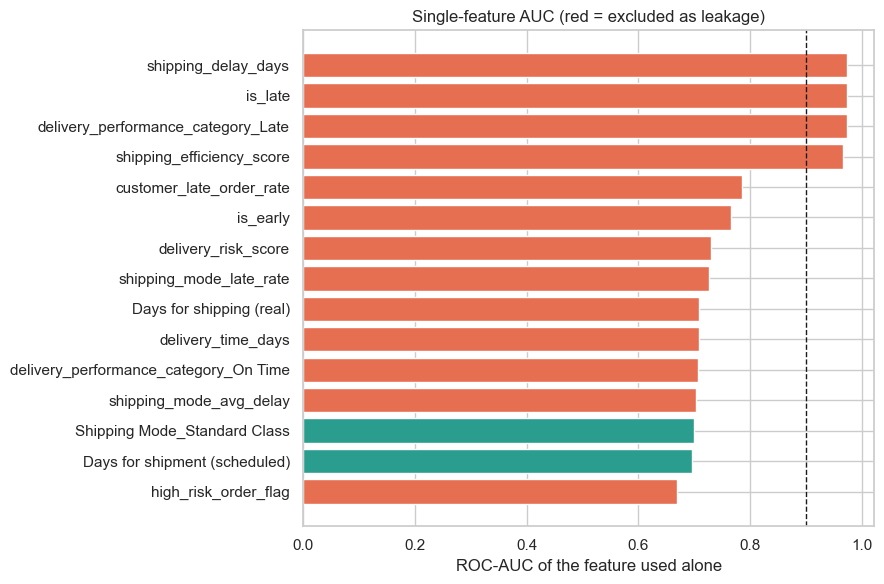

In [8]:
suspicious = scan[(scan['auc'] > 0.90) & (~scan['on_exclusion_list'])]
print('Features above 0.90 AUC that are NOT on the exclusion list:')
print(suspicious.to_string(index=False) if len(suspicious) else '  none')

top = scan.head(15).iloc[::-1]
colors = ['#e76f51' if f else '#2a9d8f' for f in top['on_exclusion_list']]
plt.figure(figsize=(9, 6))
plt.barh(top['feature'], top['auc'], color=colors)
plt.axvline(0.90, color='k', ls='--', lw=1)
plt.title('Single-feature AUC (red = excluded as leakage)')
plt.xlabel('ROC-AUC of the feature used alone')
plt.tight_layout(); plt.savefig(FIG_DIR / '02_leakage_scan.png', dpi=150, bbox_inches='tight'); plt.show()

If the list above is empty, nothing suspicious remains outside the exclusion list. If a feature does show up, investigate it before going further and do not assume it is safe.

### 3.2 Build the candidate feature set

In [9]:
drop_now = set(all_listed) | {TARGET, DATE_COL}
candidates = [c for c in df.columns if c not in drop_now]
X = df[candidates].copy()

# booleans -> 0/1 so they behave as numeric flags
for c in X.columns:
    if pd.api.types.is_bool_dtype(X[c]):
        X[c] = X[c].astype('int8')

is_cat = lambda s: (not pd.api.types.is_numeric_dtype(s)) and (not pd.api.types.is_datetime64_any_dtype(s))
cat_cols = [c for c in X.columns if is_cat(X[c])]
num_cols = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
print(f'Candidates: {len(candidates)}  (numeric/flag: {len(num_cols)}, categorical: {len(cat_cols)})')

Candidates: 45  (numeric/flag: 38, categorical: 7)


In [10]:
removed = {}

# constant columns carry no information
const = [c for c in X.columns if X[c].nunique(dropna=False) <= 1]
removed['constant'] = const

# categorical columns with too many levels
card = X[cat_cols].nunique().sort_values(ascending=False)
print('Categorical cardinality:'); print(card.to_string())
too_many = card[card > 200].index.tolist()
removed['high_cardinality_(>200)'] = too_many

# near-duplicate numeric columns (|corr| > 0.98): keep the first of each pair
keep_num = [c for c in num_cols if c not in const]
corr = X[keep_num].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
dup = [c for c in upper.columns if (upper[c] > 0.98).any()]
removed['near_duplicate_(corr>0.98)'] = dup

for k, v in removed.items():
    print(f'\n{k}: {v if v else "none"}')

Categorical cardinality:
Order Country       164
Category Name        50
Order Region         23
Department Name      11
Type                  4
profit_category       4
revenue_category      3

constant: ['Product Status']

high_cardinality_(>200): none

near_duplicate_(corr>0.98): ['Sales', 'Order Item Total', 'Order Profit Per Order', 'Product Price', 'profit_margin']


In [11]:
drop_more = set(const) | set(too_many) | set(dup)
final_num = [c for c in num_cols if c not in drop_more]
final_cat = [c for c in cat_cols if c not in drop_more]
print(f'Final features -> numeric/flag: {len(final_num)}, categorical: {len(final_cat)}')
print('\nNumeric/flag:', final_num)
print('\nCategorical:', final_cat)

Final features -> numeric/flag: 32, categorical: 7

Numeric/flag: ['Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Latitude', 'Longitude', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'is_profit_outlier', 'order_quarter', 'order_month', 'order_week', 'order_day_of_week', 'order_is_weekend', 'order_is_holiday', 'order_total_revenue', 'high_value_order_flag', 'loss_order_flag', 'customer_orders_to_date', 'premium_product_flag', 'high_discount_flag', 'Shipping Mode_Same Day', 'Shipping Mode_Second Class', 'Shipping Mode_Standard Class', 'Customer Segment_Corporate', 'Customer Segment_Home Office', 'Market_Europe', 'Market_Latam', 'Market_Pacific Asia', 'Market_Usca']

Categorical: ['Type', 'Category Name', 'Department Name', 'Order Country', 'Order Region', 'revenue_category', 'profit_category']


### 3.3 Final check on the cleaned feature set

Same scan again, now on the features I intend to train on. The strongest single feature should be something a planner would expect, such as scheduled shipping days or shipping mode.

In [12]:
post = single_feature_auc(pd.concat([X[final_num], df[TARGET]], axis=1), final_num, TARGET)
print(post.head(10).to_string(index=False))
assert post['auc'].max() < 0.90, 'A single feature is still too predictive. Investigate before training.'
print('\nOK: no single feature above 0.90 AUC.')

                      feature      auc
 Shipping Mode_Standard Class 0.700209
Days for shipment (scheduled) 0.696444
   Shipping Mode_Second Class 0.585082
       Shipping Mode_Same Day 0.509593
     Order Item Product Price 0.505219
            Benefit per order 0.503921
            is_profit_outlier 0.503573
   Customer Segment_Corporate 0.503341
              loss_order_flag 0.503275
          Order Item Quantity 0.503262

OK: no single feature above 0.90 AUC.


## 4. Evaluation boundaries

The split is chronological: the model is trained on the earliest orders, tuned on the next period, and tested on the most recent period it has never seen. A random split would let the model learn from the future and overstate performance.

| Split | Used for | Rule |
|---|---|---|
| **Train** (first 68%) | fitting models, cross-validation, tuning | |
| **Validation** (next 12%) | choosing between models and choosing the decision threshold | |
| **Test** (last 20%) | one final evaluation, in notebook 09 only | never used in notebook 08 |

One extra rule: the data has one row per order item, so one order can have several rows with the same shipping outcome. If those rows landed in different splits, the model would be tested on orders it had effectively seen. I place each order by its earliest date and keep every row of that order in the same split.

In [13]:
has_id = ORDER_ID in df.columns
# an order's position in time is its earliest date, so every item of an order moves together
df['order_start'] = df.groupby(ORDER_ID)[DATE_COL].transform('min') if has_id else df[DATE_COL]

d = df[['order_start'] + ([ORDER_ID] if has_id else [])].copy()
d = d.sort_values(['order_start'] + ([ORDER_ID] if has_id else []), kind='stable')
n = len(d)
pos = np.arange(n)
i_val, i_test = int(n * TRAIN_SHARE), int(n * (TRAIN_SHARE + VAL_SHARE))
d['split'] = np.where(pos < i_val, 'train', np.where(pos < i_test, 'validation', 'test'))

if has_id:
    before = d['split'].copy()
    d['split'] = d.groupby(ORDER_ID)['split'].transform('first')     # fixes an order cut in two by a boundary
    print(f'Rows moved so that each order stays in one split: {(before != d["split"]).sum():,}')
else:
    print('No Order Id column found: items of one order cannot be kept together.')

df['split'] = d['split'].reindex(df.index)

# --- checks ---
rng = df.groupby('split')['order_start'].agg(['min', 'max'])
assert rng.loc['train', 'max'] <= rng.loc['validation', 'min'] <= rng.loc['validation', 'max'] <= rng.loc['test', 'min'], \
    'Splits overlap in time.'
if has_id:
    sets = {s: set(g[ORDER_ID]) for s, g in df.groupby('split')}
    assert not (sets['train'] & sets['validation'] or sets['train'] & sets['test'] or sets['validation'] & sets['test']), \
        'The same order appears in more than one split.'
print('OK: splits are in chronological order and no order appears in two splits.\n')

boundaries = (df.groupby('split')
                .agg(rows=(TARGET, 'size'), first_order=('order_start', 'min'),
                     last_order=('order_start', 'max'), late_rate=(TARGET, 'mean'))
                .loc[['train', 'validation', 'test']])
boundaries['late_rate'] = boundaries['late_rate'].round(4)
boundaries

Rows moved so that each order stays in one split: 1
OK: splits are in chronological order and no order appears in two splits.



,rows,first_order,last_order,late_rate
split,,,,
train,122752,2015-01-01 00:00:00,2016-12-17 15:27:00,0.5491
validation,21664,2016-12-17 15:48:00,2017-04-22 15:17:00,0.5469
test,36103,2017-04-22 15:38:00,2018-01-31 23:38:00,0.5465


### 4.1 Does the data change between train and test?

If a feature looks very different in the test period, the model is being asked to extrapolate. I compare train and test for each numeric feature with the Kolmogorov–Smirnov statistic (0 = identical distributions, 1 = completely different).

In [14]:
tr = df[df['split'] == 'train'].sample(20_000, random_state=SEED, replace=True)
te = df[df['split'] == 'test'].sample(20_000, random_state=SEED, replace=True)
drift = []
for c in final_num:
    a, b = tr[c].dropna().astype(float), te[c].dropna().astype(float)
    if a.nunique() > 1 and len(b):
        drift.append((c, ks_2samp(a, b).statistic))
drift = pd.DataFrame(drift, columns=['feature', 'ks_train_vs_test']).sort_values('ks_train_vs_test', ascending=False)
print(drift.head(10).round(3).to_string(index=False))
flagged = drift[drift['ks_train_vs_test'] > 0.20]
print('\nFeatures with KS > 0.20:', flagged['feature'].tolist() if len(flagged) else 'none')

                 feature  ks_train_vs_test
           Market_Europe             0.358
 customer_orders_to_date             0.324
              order_week             0.247
             order_month             0.243
             Market_Usca             0.210
           order_quarter             0.198
     Order Item Quantity             0.158
Order Item Product Price             0.138
     Market_Pacific Asia             0.120
     order_total_revenue             0.117

Features with KS > 0.20: ['Market_Europe', 'customer_orders_to_date', 'order_week', 'order_month', 'Market_Usca']


Any feature flagged above 0.20 deserves a second look. For example, a running count of a customer's orders grows by construction, so its range in the test period sits above the training range. If a feature drifts for a structural reason like that, either keep it and note the risk, or add it to the exclusion list and re-run this notebook.

## 5. Missing values

In [15]:
miss = X[final_num + final_cat].isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
print('Columns with missing values:'); print(miss.round(4).to_string() if len(miss) else '  none')

Columns with missing values:
  none


Imputation is not done here. It happens inside the modelling pipeline in notebook 08, so the imputer is fitted on training data only and no information flows in from later periods.

## 6. Save the modelling table and the manifest

In [16]:
keep_id = [ORDER_ID] if ORDER_ID in df.columns else []
model_df = pd.concat([df[[DATE_COL] + keep_id + ['split']], X[final_num + final_cat], df[[TARGET]]], axis=1)
model_df = model_df.sort_values(DATE_COL, kind='stable').reset_index(drop=True)
model_df.to_csv(OUT_DIR / 'model_input.csv.gz', index=False, compression='gzip')

manifest = {
    'target': TARGET,
    'date_col': DATE_COL,
    'order_id': ORDER_ID if ORDER_ID in df.columns else None,
    'prediction_moment': 'order placement',
    'numeric': final_num,
    'categorical': final_cat,
    'split_rule': f'chronological {TRAIN_SHARE:.0%}/{VAL_SHARE:.0%}/{1-TRAIN_SHARE-VAL_SHARE:.0%}; all rows of an order stay in one split',
    'evaluation_boundaries': {
        s: {'rows': int(r['rows']), 'from': str(r['first_order'].date()),
            'to': str(r['last_order'].date()), 'late_rate': float(r['late_rate'])}
        for s, r in boundaries.iterrows()
    },
    'excluded': {**{k: [c for c in v if c in df.columns] for k, v in LEAKAGE.items()},
                 **{k: v for k, v in removed.items() if v}},
}
with open(OUT_DIR / 'feature_manifest.json', 'w') as f:
    json.dump(manifest, f, indent=2)

print(f'Saved {model_df.shape[0]:,} rows x {model_df.shape[1]} columns to {OUT_DIR / "model_input.csv.gz"}')
print(f'Saved manifest to {OUT_DIR / "feature_manifest.json"}')

saved_cols = pd.read_csv(OUT_DIR / 'model_input.csv.gz', nrows=0).columns
assert 'split' in saved_cols, 'The saved file has no split column. Something went wrong while saving.'
print("Verified: the saved file has the 'split' column. You can now run notebook 08.")

Saved 180,519 rows x 43 columns to E:\Supply Chain Project\Datasets\Model Input\model_input.csv.gz
Saved manifest to E:\Supply Chain Project\Datasets\Model Input\feature_manifest.json
Verified: the saved file has the 'split' column. You can now run notebook 08.


## Summary

- **Target:** `Late_delivery_risk` means the shipment took longer than scheduled. The late rate and its drift over time are documented above.
- **Timing:** predictions are made at order placement, so only information known then is allowed.
- **Safe features:** outcome-derived, post-order, full-history, time-trend, identifier and high-cardinality columns were removed with a reason for each. The AUC scan confirmed no remaining single feature is suspiciously predictive.
- **Boundaries:** chronological train / validation / test, with each order kept in one split. The test period is reserved for notebook 09.
- **Next:** `08_late_delivery_model_training_selection.ipynb` trains baselines and candidate models and selects one using training and validation evidence only.